# OCR do *Livro de Registro de Leis nº 1* (São Carlos, 1892–1894)

Um reconhecedor de linhas de 64 MB, ajustado com transcrições que o Gemini fez de *outras* páginas do livro, e uma
pós-correção com recursos de época levam o WER de **64,6% para 18,7%** nas três páginas reservadas, contra o
gabarito oficial. A leitura roda em CPU, sem LLM.

Este notebook só lê resultados salvos (`records/e20`, `records/x02`, `records/e19`). Não treina, não busca, não decodifica.

In [ ]:
# In Colab, fetch only the records and pages this notebook reads (sparse clone, ~10 s). Locally, use the repo.
import subprocess, sys
from pathlib import Path
from IPython.display import HTML, display
REPO, BRANCH = 'https://github.com/DeguShi/OCR-pipeline-historical-data', 'main'
PATHS = ['notebooks', 'records/e20/eval', 'records/x02/run_20261119/report', 'records/e19', 'data/images',
         'data/ground_truth', 'data/ground_truth_gemini', 'data/extra/teste']
found = [p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'notebooks/demo_lib.py').exists()]
if not found:
    dest = Path('/content/OCR-pipeline-historical-data')
    if not dest.exists():
        subprocess.run(['git', 'clone', '-q', '--depth', '1', '--filter=blob:none', '--sparse', '-b', BRANCH,
                        REPO, str(dest)], check=True)
        subprocess.run(['git', '-C', str(dest), 'sparse-checkout', 'set', *PATHS], check=True)
    found = [dest]
ROOT = found[0]
sys.path.insert(0, str(ROOT / 'notebooks'))
import demo_lib as L
G = L.grid()

def show_page_book1(set_, ref, page):
    L.show_image(L.page_image(set_, page), f'Página {page}')
    ref_text = L.reference(set_, ref, page)
    runs = []
    for rec, dec, label in L.SHOWCASE:
        r = L.e20_page(set_, rec, dec, ref, page)
        if r:
            runs.append(L.PageRun(label, r.text, r.wer))
    display(HTML(L.runs_table_html(runs, ref_text)))

def show_page_atas(page):
    d = L.DEMO / 'livro_atas'
    rep = L.load_json(L.E19 / 'e19_report.json')['runs']
    L.show_image(d / f'{page}.jpg', f'Livro de Atas, página {page}')
    runs = [L.PageRun('v6 padrão', (d / f'{page}_default.txt').read_text(), rep['default']['per_page'][str(page)]),
            L.PageRun('v6, imagem escolhida sem gabarito', (d / f'{page}_lex.txt').read_text(),
                      rep['lex']['per_page'][str(page)])]
    display(HTML(L.runs_table_html(runs, (d / f'{page}_ref.txt').read_text())))

## 1. Dados e protocolo

- **12 páginas com GT oficial** da Fundação Pró-Memória. Toda escolha é feita em 9 delas (**ajuste**); as outras 3
  (**reservadas**: 7, 10 e 12) só avaliam.
- **78 páginas de treino**, com transcrições do Gemini como rótulo. Nenhum GT humano vira rótulo.
- **10 páginas de teste** do mesmo livro e **20 páginas de outro livro** (Livro de Atas). A referência delas é a
  transcrição do Gemini, sem revisão humana.

Nenhuma página avaliada entra em treino ou escolha, e a configuração foi congelada antes da avaliação.

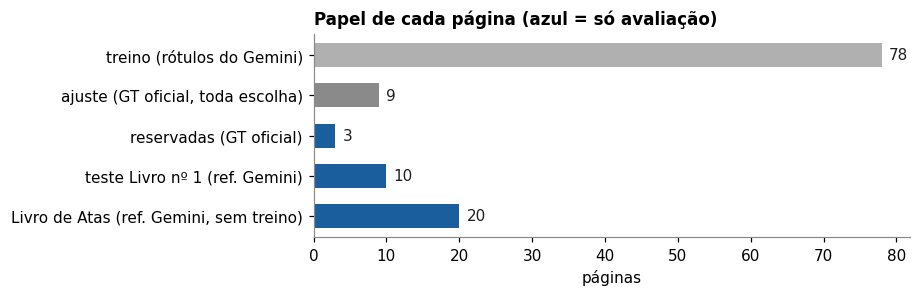

In [ ]:
L.plot_split()

## 2. O pipeline (v6)

Cada foto gera duas imagens. A de segmentação recebe contraste e perde a pauta. A de reconhecimento fica sem
tratamento, porque binarizar ajuda o segmentador, mas custa cerca de 10 pontos ao reconhecedor, que foi treinado com
imagens reais.

O reconhecedor, **st_c1m**, é o *medium* publicado (PP-OCRv6, Kraken) com ajuste fino em 2.425 linhas rotuladas pelo
Gemini. A pós-correção, **P6**, parte das probabilidades do CTC e não só do texto lido. Ela reescora candidatas do
dicionário de época e depois escolhe a sequência da linha com um Viterbi de trigramas.

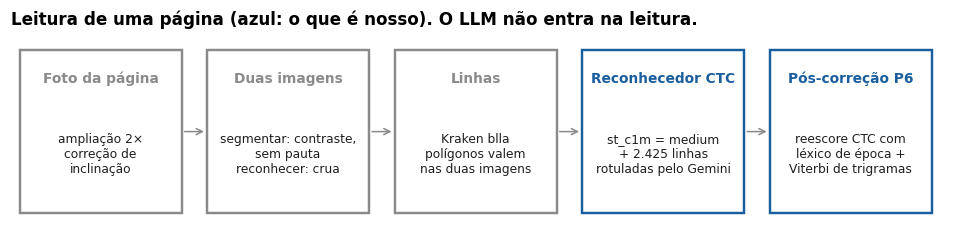

In [ ]:
L.plot_pipeline()

O dicionário e os trigramas vêm de 443 livros do Gutenberg (autores nascidos entre 1790 e 1875), de 3.565 leis de
São Paulo (1889–1910) e do texto das 78 páginas de treino. Com um léxico moderno, *approvação* virava *aprovação*,
o que conta como erro.

Os parâmetros foram escolhidos por uma busca gulosa condicional: uma etapa por vez, sempre testada sobre o melhor
conjunto atual, para captar interações entre etapas. No mesmo espaço, ela chegou a 36,00% de WER no ajuste, contra
43,62% da busca aleatória, com menos da metade das avaliações. As buscas gulosas somaram cerca de 2.300 avaliações e
92 horas.

## 3. Progressão das versões

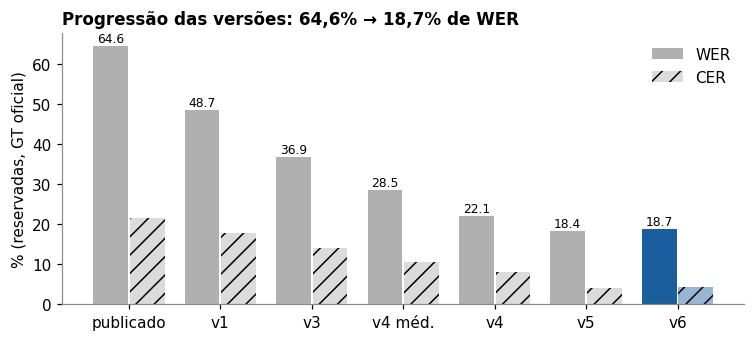

In [ ]:
L.plot_progression()

Cada versão soma peças à anterior, então o tamanho de cada degrau depende da ordem em que a peça entrou; a
contribuição de cada peça isolada está na Seção 4. A v6 repete a configuração da v5, mas com um reconhecedor
retreinado numa cadeia que não usou nenhuma página avaliada. Por isso ela é a versão relatada, mesmo com WER um pouco
maior nas reservadas.

O "publicado" desta tabela é a linha de base original do projeto. Medida de novo na comparação da Seção 4, a mesma
condição dá 60,8%.

## 4. Comparação controlada com a literatura

A comparação cruza seis reconhecedores com até cinco formas de transformar a saída do CTC em texto (decodificação
ou pós-correção), todos sobre a mesma imagem e a mesma segmentação. R4 e R5 são o TraPrInq e o McCATMuS ajustados
**com os mesmos rótulos** do nosso reconhecedor. Assim, a diferença entre R1 e R4 mede o modelo de partida, não os
rótulos. A cor segue o WER em escala logarítmica.

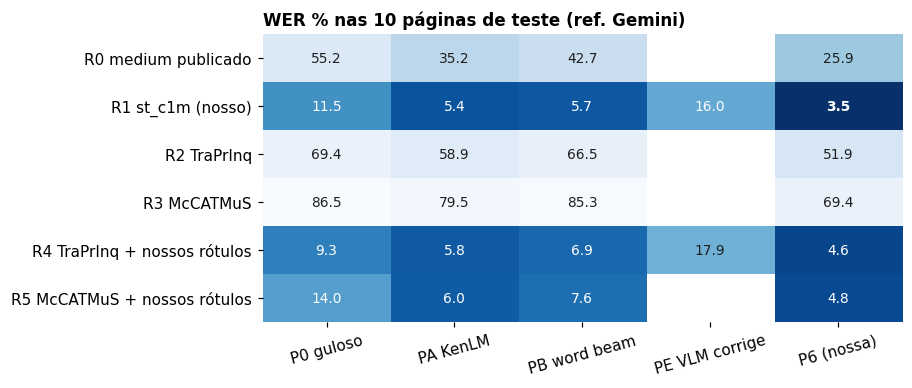

In [ ]:
L.plot_grid('test10/gemini', 'WER % nas 10 páginas de teste (ref. Gemini)')

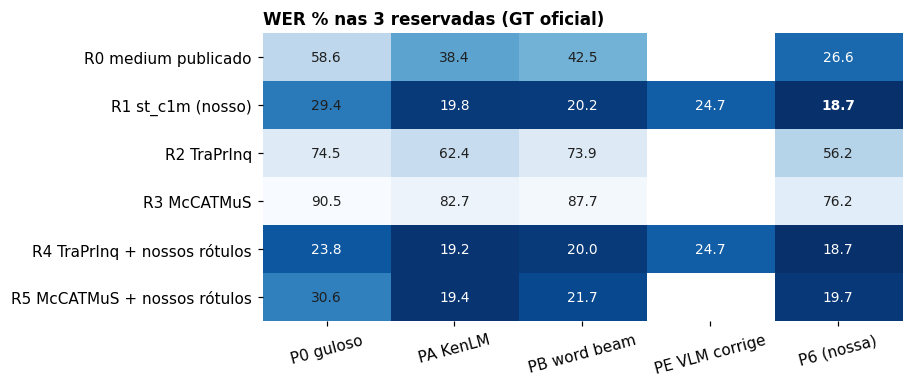

In [ ]:
L.plot_grid('heldout/oficial', 'WER % nas 3 reservadas (GT oficial)')

Cada ponto é a diferença de WER entre a v6 e um sistema, com IC95 de um bootstrap pareado. As linhas "181 configs"
vêm do X02, que repetiu a busca do KenLM com 181 configurações, quase o dobro das 92 originais.

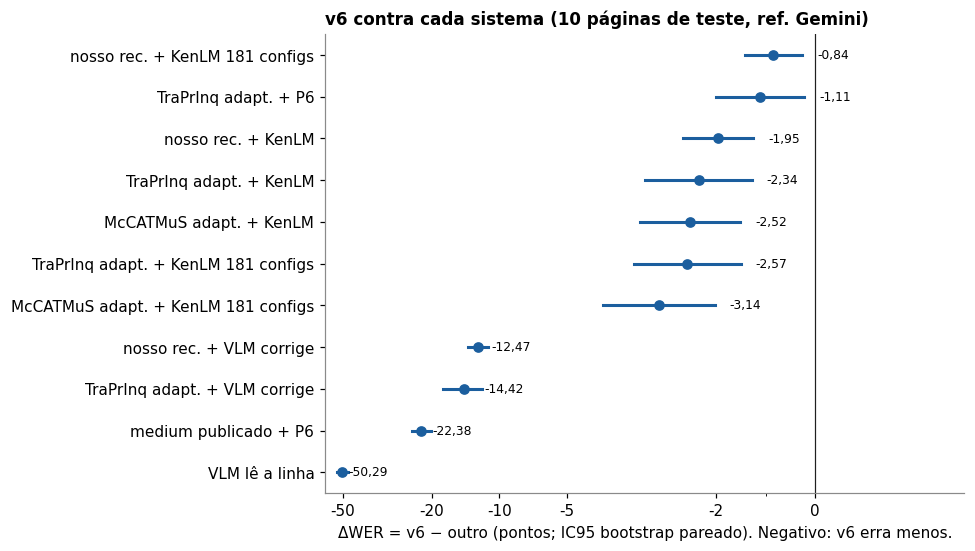

In [ ]:
L.plot_paired()

No teste, nenhum intervalo cruza o zero: a v6 erra menos que cada um dos 11 sistemas. Contra a melhor receita
publicada, o TraPrInq ajustado com KenLM, a v6 erra 2,34 pontos a menos. Desses, 1,24 vêm de trocar o KenLM pela P6
no mesmo reconhecedor, e o 1,11 restante vem de trocar o reconhecedor. Com a busca do KenLM quase dobrada, a
diferença continua (−2,57).

Nas 3 reservadas, contra o GT oficial, a diferença para essa mesma receita é de −0,47 [−2,07; 1,13]. O intervalo
contém o zero, então ali os dois sistemas não se distinguem.

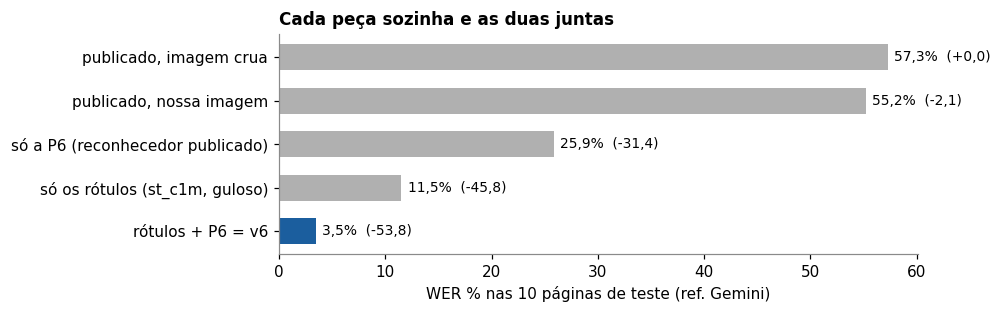

In [ ]:
L.plot_gains()

Cada peça sozinha já ajuda muito, e os rótulos ajudam mais que a pós-correção. Combinadas, chegam a 3,5%.

## 5. Página por página

De cada conjunto entram as duas páginas com o WER da v6 mais próximo da mediana. A regra é fixa, para não escolher
as páginas em que a v6 vai melhor. Para cada sistema aparecem as primeiras 70 palavras: o erro riscado e, acima
dele, a palavra da referência. Um ordinal escrito "3.º" aparece como "3 º" contra "3º", porque a pontuação é
removida antes da comparação, como na métrica.

### Reservadas, contra o GT oficial (páginas 7 e 12)

#### Página 7 (reservada, GT oficial)

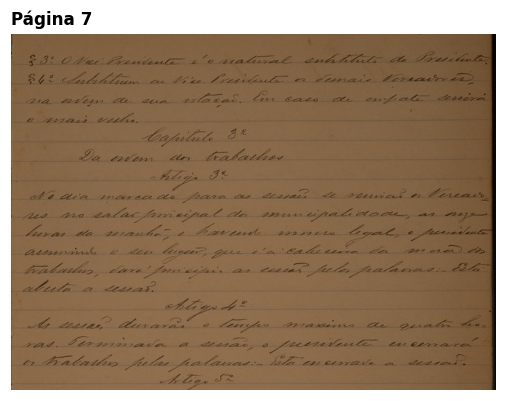

sistema,WER,primeiras 70 palavras (erroreferência)
"Publicado (medium, imagem crua, guloso)","62,8%",3º oviec prensente éao vice presidente é o natural subititutesubstituto do presidente 4º subibtrum desubstituem ao vice creiseute es deaispresidente os demais vereadores na ondemordem de sua iotaçad envotação em caso de empate serivaservirá o mais veclre capitule 32velho capitulo 3º da orenordem dos trabachos eartige 3etrabalhos artigo 3º no dia marcado para as sessais se renirar o vircado ressessões de reunião os vereadores no salar pricipalsalão principal da muricipalidademunicipalidade as ozeonze horas da manhomanhã e havennde inerohavendo meio legal o peuisiate armindo apresidente assumindo o seu lugerlugar que cé a cabeceiva du meracadeira da sessão dos trabarlus davó pricipistrabalhos dará principio as ussor pelos palairas esta abutasessões pelas palavras está aberta a sessaõ chtigssessão artigo 4º as sessae duvavas asessões deixarão o tempo maximsmaximo de quatrequatro horas perminadaterminada a sessao e puesivente encenará or trabathessessão o presidente encerrará os trabalhos …
VLM lê a linha (Qwen2.5-VL 7B),"45,6%",3º o vice presidente é o natural substituto do presidente 4º substituisubstituem ao vice presidente o senhor fernandoos demais vereadores na alçpordem de sua ntaçãvotação em caso de enfate teriváempate servirá o mais velho capitulo 3º da alien doordem dos trabalhos antigoartigo 3º no dia marcado para as sessões de vereador nasreunião os vereadores no salas principais dosalão principal da municipalidade as aux luraonze horas da marinhamanhã e havendo numeromeio legal o prefeito assimindopresidente assumindo o seu lugar que é a calcáriacadeira da moradasessão dos trabalhos daredará principio as sessões pelapelas …
Nosso reconhecedor + VLM corrige,"20,9%",3 º3º o vice presidente é o natural substituto do presidente 4 º subsbitrem4º substituem ao vice presidente os demais vereadores na ordem de sua instaçãovotação em caso de empate servirá o mais velho capitulo 33º da ordem dos trabalhos astigoartigo 3º no dia marcado para as sessões se reunirãode reunião os vereadores nos no salão principal da municipalidade as ouze luraonze horas da manhã e havendo númeromeio legal o presidente assumindo o seu lugar que é a …
TraPrInq adaptado + KenLM (melhor receita publicada),"18,1%",3 º3º o vee frendentevice presidente é o natural substituto do presidente 4 º4º substituem ao vice presidente os demais vereadores na ordem de sua estaçãovotação em caso de empate servirá o mais velho capitulo 3 º3º da ordem dos trabalhos artigo 3 º3º no dia marcado para as sessões se reunirãode reunião os vergadoresvereadores no salão principal da municipalidade as onze horas da manhã e havendo numeromeio legal o presidente assumindo o seu lugar que é á cabeceiraa cadeira …
Nosso reconhecedor + KenLM,"18,6%",3 º3º o vice presidente é o natural substituto do presidente 4 º4º substituem ao vice presidente os demais vereadores na ordem de sua istaçãovotação em caso de empate servirá o mais velho capitulo 33º da ordem dos trabalhos artigo 33º no dia marcado para as sessões se reunirãode reunião os erradoresvereadores no salão principal da municipalidade as onze horas da manhamanhã e havendo neromeio legal o presidente assumindo o seu lugar que é …
v6: nosso reconhecedor + P6,"18,6%",3 º3º o vice presidente é o natural substituto do presidente 4 º4º substituem ao vice presidente os demais vereadores na ordem de sua estaçãovotação em caso de empate servirá o mais velho capitulo 33º da ordem dos trabalhos artigo 3 º3º no dia marcado para as sessões se reunirãode reunião os vereadores no salão principal da municipalidade as onze horas da manhamanhã e havendo numeromeio legal o presidente assumindo o seu lugar que é …


In [ ]:
show_page_book1('heldout', 'oficial', 7)

#### Página 12 (reservada, GT oficial)

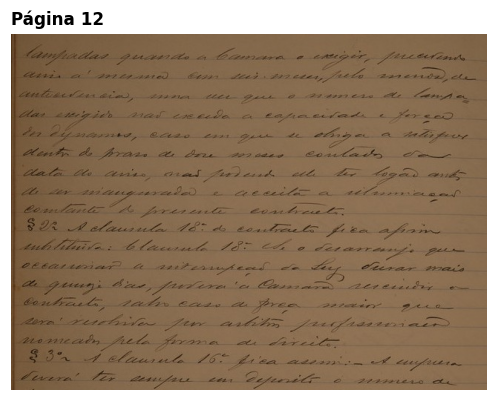

sistema,WER,primeiras 70 palavras (erroreferência)
"Publicado (medium, imagem crua, guloso)","59,8%",ampadaslampadas quando a camara a exigir precitendo airi aprecisando aviso à mesma ancom seis meurmeses pelo menos de antoerdencia ina uuantecedencia uma vez que a nimeroo numero de lampa das excigido nad exeidalampadas exigir não exceda a capacisadecapacidade e força en dynamesfunção das dynamos caso enem que ce obigase obriga a ntispor dentenotificar dentro do praso de prars de doredoze meses contadescontados da data do airco arad podendeanno não podendo elle ter logadlogar antes de ser mauguradainaugurada e acceita a silaças comtante deilluminação constante do presente contraute 2econtracto 2º a clausula 18e de18ª do contracto fica afsin iubtituidaassim substituida clausula 18e18ª se a desaranjoo desarranjo que occasionarocasionar a niterrupeadinterrupção da luy divarluz durar mais de quizequinze dias …
VLM lê a linha (Qwen2.5-VL 7B),"55,2%",lançadaslampadas quando a camara o exigir mediante avis a mesmosexigir precisando aviso à mesma com sui mescoseis meses pelo mesmomenos de autocertificaçãoantecedencia uma vez que o número da lampa das enigidos mas creudanumero de lampadas exigir não exceda a capacidade e forças em dyscursofunção das dynamos caso em que se obriga a interpornotificar dentro do prazopraso de doisdoze meses contados da data de anio aras pendem eli tedo anno não podendo elle ter logar antsantes de ser inauguradoinaugurada e aceitaacceita a iluminação contanteilluminação constante do presente contrato icontracto 2º a clausula 1818ª do contratocontracto fica afimassim substituida clausula 18 º do disposto18ª se o desarranjo que ocasuarocasionar a miterrupção deinterrupção da luz durar mais de quinze dias …
Nosso reconhecedor + VLM corrige,"28,0%",lampadas quando a camara o exigir precedendo arvio a exigir precisando aviso à mesma com seis meses pelo menos de antecedênciaantecedencia uma vez que o númeronumero de lampadas exigidosexigir não exceda a capacidade e força dos dinamosfunção das dynamos caso em que se obriga a satisfazernotificar dentro do prazopraso de doisdoze meses contados da data do arizoanno não podendo elle ter logadologar antes de ser inaugurada e aceitaacceita a situaçãoilluminação constante do presente contrato 2 ºcontracto 2º a cláusula 18 ºclausula 18ª do contratocontracto fica assim …
TraPrInq adaptado + KenLM (melhor receita publicada),"20,1%",lampadas quando a camara oa exigir precedendo anio áprecisando aviso à mesma com seis mezesmeses pelo menos de antecedencia uma vez que o numero de lampadas exigidoexigir não exceda a capacidade e força dos dunamosfunção das dynamos caso em que se obriga a satisfzernotificar dentro do praso de doze mezesmeses contados da data do avisoanno não podendo elle ter lugarlogar antes de ser inaugurada e acceita a illuminação constante do presente contracto 2 º2º a clausula 18 ª18ª do contracto …
Nosso reconhecedor + KenLM,"21,8%",lampadas quando a camara oa exigir precedendo ario áprecisando aviso à mesma com seis mezesmeses pelo menos de antecedencia uma vez que o numero de tampadas exigidolampadas exigir não exceda a capacidade e força dosfunção das dynamos caso em que se obriga a satisfzernotificar dentro do praso de doze mezesmeses contados da data do avisoanno não podendo elle ter lugarlogar antes de ser inaugurada e acceita a illuminação constante do presente contracto 2 º2º a clausula 18 º18ª do contracto …
v6: nosso reconhecedor + P6,"20,5%",lampadas quando a camara oa exigir precedendoprecisando aviso áà mesma com seis mezesmeses pelo menos de antecedencia uma vez que o numero de lampadas exigidoexigir não exceda a capacidade e força dos dunamosfunção das dynamos caso em que se obriga a satisfazernotificar dentro do praso de doze mezesmeses contados da data do avisoanno não podendo elle ter lugarlogar antes de ser inaugurada e acceita a illuminação constante do presente contracto 2 º2º a clausula 18 º18ª …


In [ ]:
show_page_book1('heldout', 'oficial', 12)

### Teste do Livro nº 1, contra o Gemini (páginas 18 e 32)

#### Página 18 (teste, ref. Gemini)

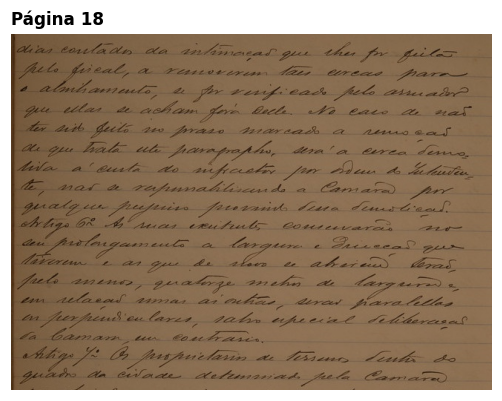

sistema,WER,primeiras 70 palavras (erroreferência)
"Publicado (medium, imagem crua, guloso)","51,9%",dias contados da intimaçadintimação que cheslhes for fiilafeita pelo firealfiscal a reouirenremoverem taes cereascercas para o abrihamentoalinhamento se pr virificadefor verificado pelo arruador que ellas se acham fora declefóra delle no carscaso de naonão ter siiosido feito no praso marcado a remoçadremoção de que trata uteeste paragrapho sevaaserá a cerca demosida acurtademolida á custa do inpractorinfractor por ordun de iulendente narordem do intendente não se repunatilisaenderesponsabilisando a camara por qualque pupiiro provino pissa demolicad eatigoqualquer prejuizo provindo dessa demolição artigo 6 º as ruas exuitrutes conseivavaoexistentes conservarão no seu prolongamento a larguealargura e druecaddirecção que tavirentiverem …
VLM lê a linha (Qwen2.5-VL 7B),"52,7%",dias contados da intimacaointimação que deve serlhes for feita pelo fiscal a ranoviria faz exearremoverem taes cercas para o alinhamento se for verificado pelo armador qu ella aarruador que ellas se acham ferá ellefóra delle no caio a nascaso de não ter ait jeitosido feito no prazopraso marcado a revo cas ouremoção de que trata uti paragraphe seraeste paragrapho será a cerca sumo mila a curtademolida á custa do sufactorinfractor por duvordem do jutentu te mas a responsabilizandointendente não se responsabilisando a camara por qualquer pessoa provindesse sinistralprejuizo provindo dessa demolição artigo 6º a suas exultub consuvarão mo com6 º as ruas existentes conservarão no seu prolongamento a largura e priscasdirecção que tiverem dare as que de todonovo se abriuas ferasabrirem terão pelo menos quatorze metros de largura e em …
Nosso reconhecedor + VLM corrige,"12,9%",dias contados da intimação que lhes for feita pelo fiscal a removerem taistaes cercas para o alinhamento se for verificado pelo aruadorarruador que ellas se acham fora delasfóra delle no caso de não ter sido feito no prazopraso marcado a remoção de que trata este parágrafoparagrapho será a cerca demolida aá custa do infractor por ordem do intendente te masnão se responsabilizandoresponsabilisando a camara por qualquer prejuizo provindo dessa demolição artigo 6 º …
TraPrInq adaptado + KenLM (melhor receita publicada),"2,5%",dias contados da intimação que lhes for feita pelo fiscal a removerem taes cercas para o alinhamento se for verificado pelo arruador que ellas se acham fóra delle no caso de não ter sido feito no praso marcado a remoção de que trata este paragrapho será a cerca demotidademolida á custa do infractor por ordem do intendeuteintendente não se responsabilisando a camara por qualquer prejuizo provindo dessa demolição artigo 6 …
Nosso reconhecedor + KenLM,"4,1%",dias contados da intimação que lhes for feita pelo fiscal a removerem taes cercas para o alinhamento se for verificado pelo arruador que ellas se acham fóra delle no caso de não ter sido feito no praso marcado a remoção de que trata este paragrapho será a cerca demolida á contacusta do infractor por ordem do iutendenteintendente não se responsabilisando a camara por qualquer prejuizo provindo dessa demolição artigo 6 …
v6: nosso reconhecedor + P6,"2,9%",dias contados da intimação que lhes for feita pelo fiscal a removerem taes cercas para o alinhamento se for verificado pelo arruador que ellas se acham fóra delle no caso de não ter sido feito no praso marcado a remoção de que trata este paragrapho será a cerca demolida á custa do infractor por ordem do intendente não se responsabilizandoresponsabilisando a camara por qualquer prejuizo provindo dessa demolição artigo 6 …


In [ ]:
show_page_book1('test10', 'gemini', 18)

#### Página 32 (teste, ref. Gemini)

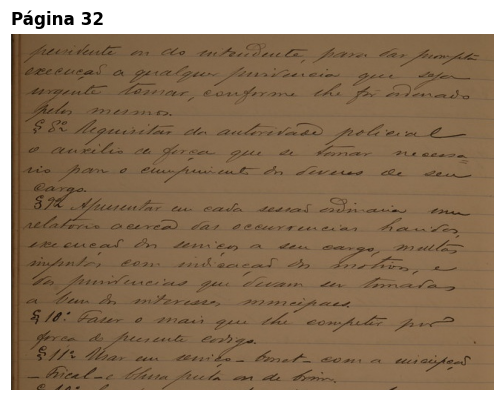

sistema,WER,primeiras 70 palavras (erroreferência)
"Publicado (medium, imagem crua, guloso)","61,4%",pecrivente onpresidente ou do intendeteintendente para pardar prompta execuçasexecução a qualquer pusvinciaprovidencia que seja urguiteurgente tomar coufirme checonforme lhe for adenadoordenado pelos mesmos auiritar8 º requisitar da autorivadeautoridade policial o auxilio de firçada força que se tomar necersa rio pantornar necessario para o empuient decumprimento dos deveres de seu cargo 92 cesentar un9 º apresentar em cada sessadsessão ordinaria uum relatorio accreaacerca das occurrincias handos exeeucad do seriçosoccorrencias havidas execução dos serviços a seu cargo multas imputosimpostas com indicaçar on motionindicação dos motivos e ous puridenciasdas providencias que decamdevam ser timadastomadas a ben de intevisses micipaes 210 faser abem dos interesses municipaes 10 º fazer o mais que thelhe competir pur porca de pesente corigo o urar un senicopor força do presente codigo 11 º usar em serviço bonet com a uircipend fricalinscripção fiscal e bhura pula onblusa preta ou …
VLM lê a linha (Qwen2.5-VL 7B),"55,6%",presidente ou do intendente para dar prompto execuçõesprompta execução a qualquer funcionárioprovidencia que seja urgente tomar conforme o presente pelo mesmo si requiritarlhe for ordenado pelos mesmos 8 º requisitar da autoridade policial o auxilio da força que se temar necessa viotornar necessario para o cumprimento dos deveres de seu cargs 392cargo 9 º apresentar em cada sessão ordinária uma relatórioordinaria um relatorio acerca das ocorrências havidos mecenas do serviçooccorrencias havidas execução dos serviços a seu cargo múltiplas inventáriosmultas impostas com indicações deindicação dos motivos as jurisdiçõese das providencias que tiveram em mãosdevam ser tomadas a vara do interior municipais 18bem dos interesses municipaes 10 º fazer o mais que lhe competecompetir por area de pimenta coruja eleitarforça do presente codigo 11 º usar em serviço bometbonet com a municipos ficalinscripção fiscal e chera pruá onblusa preta ou …
Nosso reconhecedor + VLM corrige,"14,5%",presidente ou do intendente para dar prompta execução a qualquer pessoaprovidencia que seja urgente tomar conforme lhe for ordenado pelos mesmos 8 º requisitar da autoridade policial o auxilio deda força que se tomartornar necessario para o cumprimento dos deveres de seu cargo 9º9 º apresentar em cada sessão ordináriaordinaria um relatóriorelatorio acerca das ocorrênciasoccorrencias havidas execução dos serviços a seu cargo multas importasimpostas com indicação dos motivos e das providênciasprovidencias …
TraPrInq adaptado + KenLM (melhor receita publicada),"5,3%",presidente ou do intendente para dar prompta execução a qualquer providencia que seja urgente tomar conforme lhe fôrfor ordenado pelos mesmos 8 º requisitar da autoridade policial o auxilio da força que se tomartornar necessario para o cumprimento dos deveres de seu cargo 929 º apresentar em cada sessão ordinaria um relatorio acerca das occurrenciasoccorrencias havidas execução dos serviços a seu cargo multas impostas com indicação dos motivos e das providencias …
Nosso reconhecedor + KenLM,"5,3%",presidente ou do intendente para dar prompta execução a qualquer providencia que seja urgente tomar conforme lhe fôrfor ordenado pelos mesmos 8 º requisitar da autoridade policial o auxilio deda força que se tomartornar necessario para o cumprimento dos deveres de seu cargo 9º9 º apresentar em cada sessão ordinaria um relatorio acerca das occurrenciasoccorrencias havidas execução dos serviços a seu cargo multas impostas com indicação dos motivos e das providencias …
v6: nosso reconhecedor + P6,"3,9%",presidente ou do intendente para dar prompta execução a qualquer providencia que seja urgente tomar conforme lhe fôrfor ordenado pelos mesmos 8 º requisitar da autoridade policial o auxilio deda força que se tomartornar necessario para o cumprimento dos deveres de seu cargo 9º9 º apresentar em cada s

In [ ]:
show_page_book1('test10', 'gemini', 32)

### Livro de Atas, outro livro e outro escrivão, sem treino (páginas 6 e 50)

Neste livro só a v6 foi rodada; a comparação com a literatura não. As duas linhas são a v6 com a imagem padrão e
com a imagem escolhida, sem gabarito, pela regra "mais palavras do dicionário de época lidas".

#### Página 6

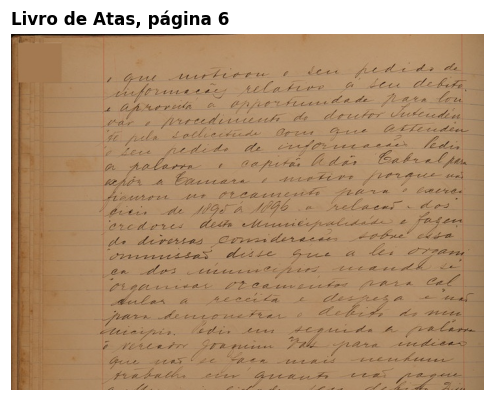

sistema,WER,primeiras 70 palavras (erroreferência)
v6 padrão,"20,5%",o que motivou o seu pedido de informações relativo aá seu debito e aproveita a opportunidade para louvar o procedimento do doutor intendemintendente pela sollicitude com que attendemattendeu o seu pedido de informações pediapedio a palavra o capitão adão carrapateirocabral para expôr a camara o motivo porque nonão figurou no orçamento para o exerce cicioexercicio de 1895 a 1895á 1896 a relação dos credores desta municipalidade e fazendo diversas considerações sobre essa ommissão disse que a …
"v6, imagem escolhida sem gabarito","18,1%",o que motivou o seu pedido de informações relativo aá seu debito e aproveita a opportunidade para louvar o procedimento do doutor intendente pela sollicitude com que attendem eattendeu o seu pedido de informações pediapedio a palavra o capitão adão carrapateirocabral para expôr a camara o motivo porque nonão figurou no orçamento para o exercicio de 1895 á 18951896 a relação dos credores desta municipalidade e fazendo diversas considerações sobre essa ommissão disse que a …


In [ ]:
show_page_atas(6)

#### Página 50

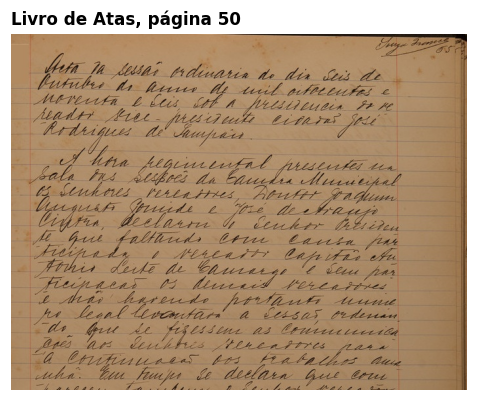

sistema,WER,primeiras 70 palavras (erroreferência)
v6 padrão,"20,7%",seria desouza franco 65 acta da sessão ordinaria do dia seis de outubro do anno de mil oitocentos e noventa e seis sob a presidencia do se redorvereador vice presidente cidadão josé rodrigues de sampaio a hora regimental presentes na sala das sessões da camara municipal os senhores vereadores doutor joaquim augusto condegomide e josé decorandode araujo cintra declarou o senhor presidem tepresidente que faltando com causa participada o vereador capitão aonioantonio leite de camargo e …
"v6, imagem escolhida sem gabarito","17,1%",seja direi29souza franco 65 acta da sessão ordinaria do dia seis de outubro do anno de mil oitocentos e noventa e seis sob a presidencia do se redor 8vicevereador vice presidente cidadão josé rodrigues de sampaio a hora regimental presentes na sala das sessões da camara municipal os senhores vereadores doutor joaquim augusto condegomide e josé decorandode araujo cintra declarou o penhor presidem tesenhor presidente que faltando com causa participada o vereador capitão antonio leite de camargo e sem participação …


In [ ]:
show_page_atas(50)

## 6. Um livro novo, sem treino

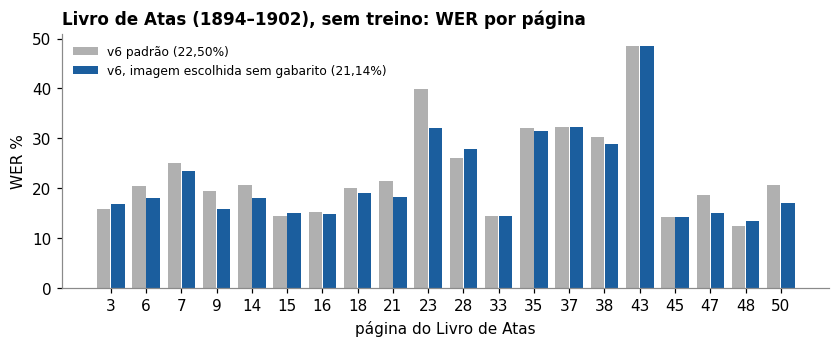

In [ ]:
L.plot_atas()

Sem nenhum ajuste a este escrivão, a v6 faz 22,50% de WER. Com a imagem escolhida pela regra, faz 21,14%: imagem
escolhida menos padrão, −1,36 [−2,38; −0,36] (bootstrap pareado). Os dois números são contra o Gemini, a mesma fonte
dos rótulos de treino, então tendem a ser otimistas.

## 7. Quanto vale a referência?

O GT oficial moderniza a grafia e escreve os ordinais como *1º*. O Gemini, e portanto o nosso reconhecedor, escreve
*1.º*. Nas 12 páginas com GT oficial, a v6 tem 19,40% de WER contra ele, e 5,6 desses pontos são convenções
juntadas ou separadas, quase todas ordinais.

Os dois sistemas ajustados com rótulos do Gemini, a v6 e o TraPrInq ajustado, caem de cerca de 19% para 6–7% quando
a referência passa a ser o Gemini. O publicado não cai. Parte da queda é, portanto, a convenção que os rótulos
ensinaram. Nenhuma das duas referências é neutra, e por isso os números aparecem contra as duas.

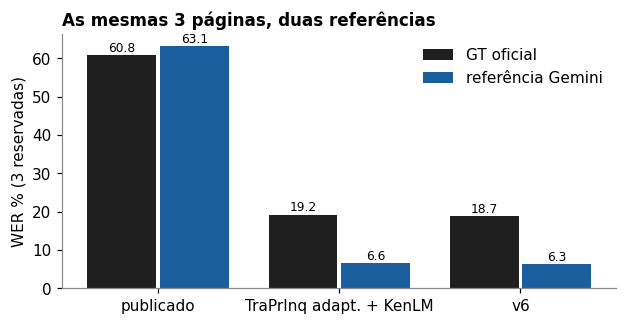

In [ ]:
L.plot_references()

## 8. Comparação final

In [ ]:
display(HTML(L.final_table_html()))

sistema,"reservadas, GT oficial","reservadas, Gemini","teste, Gemini"
"Publicado (medium, imagem crua)",60.79,63.10,57.28
"TraPrInq publicado, imagem crua",79.84,78.31,73.73
VLM lê a linha,49.29,50.30,53.78
Nosso reconhecedor + VLM corrige,24.72,16.57,15.97
TraPrInq adaptado + KenLM (181 configs),19.21,7.23,6.06
TraPrInq adaptado + P6,18.74,5.42,4.60
Nosso reconhecedor + KenLM (181),19.69,8.58,4.33
v6 (nosso reconhecedor + P6),18.74,6.33,3.49
